# Single Quantum Particle in a 1D Harmonic Oscilator


In [3]:
%pip install numpy
%pip install matplotlib
%pip install tqdm
%pip install statsmodels

  Using cached numpy-2.5.5-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.5-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (15.7 MB)

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
  Using cached matplotlib-3.11.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyp

In [ ]:
import math
import random
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
from typing import Generator, Callable

def wavefunction(x: float, alpha:float = 1): return math.exp(-alpha*x*x)

def pdf(x: float, alpha: float = 1): return wavefunction(x, alpha)**2

def sample_pdf(pdf:Callable[[float], float], initial_sample: float = 0, sigma: float = 1, max_samples=10000) -> Generator[tuple[float, float]]:
    r1 = initial_sample
    N_samples = 0
    N_accepted = 0
    
    while N_samples < max_samples:
        r2 = r1 + random.gauss(mu=0, sigma=sigma)
        
        w = pdf(r2)/pdf(r1)
        u = random.uniform(0,1)

        if u < min(1.0, w):
            N_samples += 1
            N_accepted += 1
            r1 = r2
        else:
            N_samples += 1

        yield r1, N_accepted/N_samples

In [ ]:
l = list(sample_pdf(  
            pdf=lambda x: pdf(x, alpha=1), 
            sigma=1.0, 
            initial_sample=0,
            max_samples=10000))

print(l)

[0, -0.4641313734731866, 0.2773993284660911, 0.2773993284660911, -0.1414142678435606, -0.1414142678435606, -0.1414142678435606, 0.371610655017958, 0.371610655017958, 0.09587981676529944, 0.19607101624967677, -0.0752373888418652, -0.15765597958098104, -0.15765597958098104, -0.8206127187015524, -0.8206127187015524, -0.9691526719831781, -1.4291585065615933, -1.2972419025035702, -1.2972419025035702, -0.9650359900852079, -0.9650359900852079, -0.9650359900852079, -0.4774525385311716, -0.4774525385311716, -0.4379033381917823, -0.665407845196607, -0.024576050481061484, -0.024576050481061484, -0.2964009997679272, -0.2964009997679272, 0.22505908598112434, -0.28311646966727244, -0.3746107199786681, -0.3746107199786681, -0.44700483519729045, 0.10849206892555457, 0.3865551350949962, 0.3865551350949962, 1.804211370348734, 0.39747292035761683, 0.39747292035761683, 0.6903826042524736, -0.3236159228114236, -0.3236159228114236, -0.3236159228114236, -0.3236159228114236, -0.3236159228114236, -0.2312294051

## Density Profile:

100%|██████████| 100/100 [00:00<00:00, 412.59it/s]


Best sigma found = 0.9595959595959596
Acceptance probability = 0.505
100
100


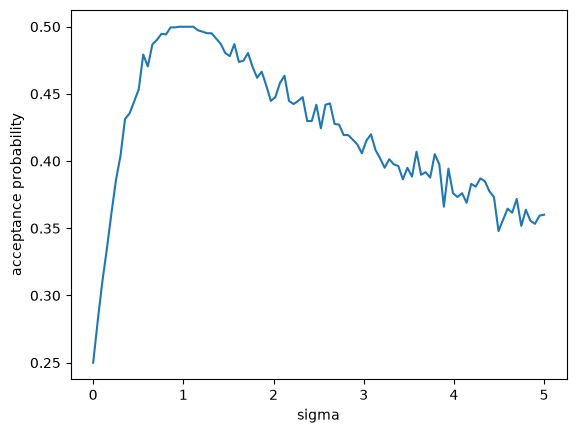

In [ ]:
def find_optimal_sigma(alpha):
    N = 1000
    # Generate a list of 100 logaritmically spaced sigma values between 0 and 10 
    sigmas = np.linspace(0, 5, 100).tolist()
    probs = []

    for sigma in tqdm(sigmas): 
        # Samples is a list of N tuples (x, prob).
        samples = list(sample_pdf(  
                    pdf=lambda x: pdf(x, alpha=alpha), 
                    sigma=sigma, 
                    initial_sample=0,
                    max_samples=N))

        probs.append(samples[-1][1])


    # Find the closest to 0.5
    index = np.argmin((np.array(probs)-0.5)**2)

    print(f"Best sigma found = {sigmas[index]}")
    print(f"Acceptance probability = {probs[index]}")

    print(len(sigmas))
    print(len(probs))
    plt.figure()
    plt.plot(sigmas, 0.5-(np.array(probs)-0.5)**2)
    plt.xlabel("sigma")
    plt.ylabel("acceptance probability")
    plt.show()
    return sigmas[index]


OPTIMAL_SIGMA = find_optimal_sigma(1)


In [50]:
def plot_histogram(histogram, min, max):
    bin_edges = np.linspace(min, max, len(histogram) + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    plt.bar(bin_centers, histogram, width=bin_edges[1] - bin_edges[0])
    plt.xlabel("Sample value")
    plt.ylabel("Frequency")
    plt.show()

def draw_denisty_profile(pdf:Callable[[float], float], n_bins, _min=None, _max=None, N=100000 ,sigma=OPTIMAL_SIGMA):
    histogram = [0 for i in range(n_bins)]

    for sample, _ in sample_pdf(pdf=pdf,
                                initial_sample=0,
                                sigma=1.0,
                                max_samples=N):
        i = int(n_bins * (sample - _min) / (_max - _min))
        i = min(i, n_bins - 1)
        histogram[i] += 1

    plot_histogram(histogram, _min, _max)
    return histogram

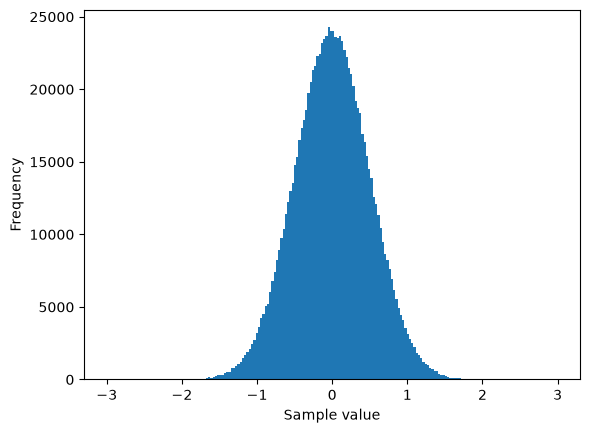

In [52]:
# Density profile amb 1 000 000 de samples
hist = draw_denisty_profile(pdf, n_bins=200, _max=-3, _min=3, N=1_000_000)

In [ ]:
OMEGA = 1.0
MASS = 1.0

ROTATIONAL_PLANKS_CONSTANT = 1.0


def potential_energy(m, omega, x):
    return 0.5*m*omega*omega*x*x